# PA2 · Question 2 · Step 1: load the data and pass Table 1

**Today's goal (about 60–90 minutes).** This step only covers four things:

1. Load Moving MNIST and split it by video.
2. Look at one video, so you know what the data is.
3. Write **three small functions**: `mirror`, `rotate`, `make_window`.
4. Run the **Table 1 checker** until every row says `OK`.

**How to use this notebook.** Run the cells from top to bottom. Edit **only** the cells marked **✏️ YOUR TURN**. The checker tells you right away whether your functions are correct.

### Kaggle settings for this step (right-hand panel → *Settings*)

| Setting | Value | Why |
|---|---|---|
| **Internet** | **On** | Needed to download the data (about 800 MB). Kaggle may ask you to verify your phone number first. |
| **Accelerator** | **None** | Step 1 does not need a GPU, so **save your weekly GPU quota** for training model A–D later. |

The notebook also runs on Colab or your own computer without changes.

In [2]:
import torch, torchvision
import numpy as np
import matplotlib.pyplot as plt

print("torch", torch.__version__, "| torchvision", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

torch 2.11.0+cu128 | torchvision 0.26.0+cu128
GPU available: True


## 1. Load the data and split it by video

`MovingMNIST(split=None)` gives **all 10,000 videos**, each with 20 frames of size 1×64×64.
The handout says: **do not** use `split="train"` or `"test"`, because those options split the *frames* of each video, not the videos.

| Videos (dataset index) | Use |
|---|---|
| 0 – 7,999 | training |
| 8,000 – 8,999 | validation |
| 9,000 – 9,999 | test |

We keep the data as `uint8` (0–255) because it uses 4× less memory, and convert to `float32 / 255` only when we use it.

In [2]:
import os, glob

ON_KAGGLE = os.path.exists("/kaggle/input")
# On Kaggle, keep the 800 MB data in /tmp so it is NOT copied into your saved notebook output.
DATA_ROOT = "/tmp/mmnist" if ON_KAGGLE else "./data"

# Optional shortcut: if you attached a Kaggle dataset that contains mnist_test_seq.npy,
# use that file instead of downloading. (If none is attached, torchvision downloads it.)
found = glob.glob("/kaggle/input/**/mnist_test_seq.npy", recursive=True) if ON_KAGGLE else []
if found:
    os.makedirs(os.path.join(DATA_ROOT, "MovingMNIST"), exist_ok=True)
    link = os.path.join(DATA_ROOT, "MovingMNIST", "mnist_test_seq.npy")
    if not os.path.exists(link):
        os.symlink(found[0], link)
    print("Using attached Kaggle file:", found[0])

ds = torchvision.datasets.MovingMNIST(root=DATA_ROOT, split=None, download=True)
videos_u8 = ds.data if hasattr(ds, "data") else torch.stack([ds[i] for i in range(len(ds))])
print(videos_u8.shape, videos_u8.dtype)      # expect: torch.Size([10000, 20, 1, 64, 64]) torch.uint8
assert tuple(videos_u8.shape) == (10000, 20, 1, 64, 64)

train_u8 = videos_u8[0:8000]
val_u8   = videos_u8[8000:9000]
test_u8  = videos_u8[9000:10000]

def to_float(v_u8):
    # uint8 0..255  ->  float32 in [0, 1]
    return v_u8.float() / 255.0

print("train / val / test videos:", len(train_u8), len(val_u8), len(test_u8))

100%|██████████| 819M/819M [00:24<00:00, 33.1MB/s] 


torch.Size([10000, 20, 1, 64, 64]) torch.uint8
train / val / test videos: 8000 1000 1000


## 2. Look at one video

**Important convention.** The handout numbers frames **1 to 20**, but Python tensor indices go **0 to 19**.
So *frame number f is stored at tensor index f − 1*. Many mistakes in this assignment come from mixing these two up.

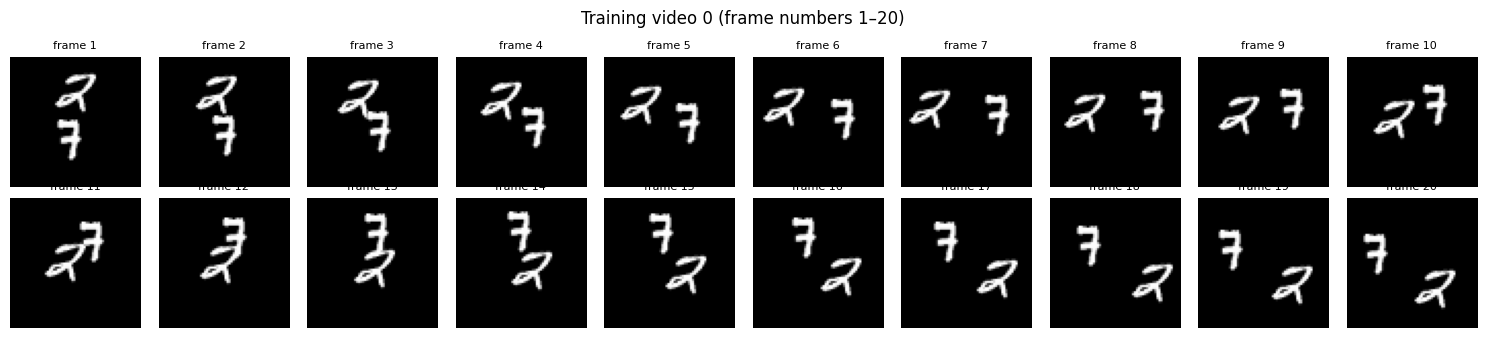

In [3]:
def show_video(video, title=""):
    # video: (20, 1, 64, 64) float tensor in [0, 1]
    fig, axes = plt.subplots(2, 10, figsize=(15, 3.4))
    for idx in range(20):
        ax = axes[idx // 10, idx % 10]
        ax.imshow(video[idx, 0].cpu(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"frame {idx + 1}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_video(to_float(train_u8[0]), "Training video 0 (frame numbers 1–20)")

## 3. ✏️ YOUR TURN: write the three functions

**Mirror M.** $(Mx)[i, j] = x[i,\ 63-j]$: a left–right flip. Row $i$ stays the same; only the **column** $j$ changes.
In a tensor of shape `(frames, channels, rows, columns)`, the columns are the **last** axis.

**Rotation R.** 90° **anticlockwise**. The handout gives the exact call: `torch.rot90(x, k=1, dims=(-2, -1))`.
$R^a$ means rotating $a$ times. A negative $a$ rotates clockwise, so $R^{-1}$ is one clockwise turn.

**Window at speed k, starting at frame number t** (Eq. 2 in the handout):

$$X = (x_t,\ x_{t+k},\ \dots,\ x_{t+4k}), \qquad Y = (x_{t+5k},\ \dots,\ x_{t+9k}),$$

keeping only target frames whose number is **≤ 20**.
Example: for $k = 2,\ t = 1$, the inputs are frames 1, 3, 5, 7, 9 and the targets are 11, 13, 15, 17, 19.

So that later code (batches, loss masking) is easy, `make_window` always returns **5** target slots, plus a `mask` that says which slots are real frames.

In [11]:
def mirror(x):
    return torch.flip(x, dims=[ -1 ])

In [8]:
def rotate(x, a=1):
    return torch.rot90(x, k= a , dims=(-2, -1))

In [9]:
a = torch.arange(1, 10).view(3, 3)
print(rotate(a, 1))    # anticlockwise: right column 3 6 9 should become the top row
print(rotate(a, -1))   # clockwise: should match the grid above
print(rotate(a, 4))    # should be the original

tensor([[3, 6, 9],
        [2, 5, 8],
        [1, 4, 7]])
tensor([[7, 4, 1],
        [8, 5, 2],
        [9, 6, 3]])
tensor([[1, 2, 3],
        [4, 5, 6],
        [7, 8, 9]])


In [30]:
# ✏️ YOUR TURN — replace each `raise NotImplementedError` with your code.

def mirror(x):
    return torch.flip(x, dims=[-1])

def rotate(x, a=1):
    return torch.rot90(x, k=a, dims=(-2, -1))


def make_window(video, t, k=1):
    in_nums  = [t + j*k for j in range(5)]           
    out_nums = [t + j*k for j in range(5, 10)]      
    X = video[[n - 1 for n in in_nums]]             
    mask = torch.tensor([n <= 20 for n in out_nums])
    Y = torch.zeros(5, *video.shape[1:], dtype=video.dtype)
    for j, n in enumerate(out_nums):              
        if n <= 20:                                
            Y[j] = video[n - 1]                   
    return X, Y, mask

## 4. Table 1 checker (do not edit; just run)

This cell calls **your** functions, the same ones your later experiments will use.

* (a)–(c) Mirror and rotation only rearrange pixels, so the difference must be **exactly 0** and `torch.equal` must be `True`.
* (d)–(e) The single bright pixel `p[7, 0, 10, 20]` (tensor indices from 0) must land in the right place. This catches flipping the wrong axis or rotating clockwise.
* (f)–(h) A video whose **frame number f contains the value f** (so tensor index i holds i + 1). The checker reads off which frame numbers your window returns.

Every row must say `OK` before you go on. **Every later result depends on these functions.**

In [31]:
torch.manual_seed(0)
x = torch.rand(20, 1, 64, 64)                       # random video
p = torch.zeros(20, 1, 64, 64); p[7, 0, 10, 20] = 1  # marker video

def bright_pixel(v):
    idx = (v == 1).nonzero()
    if len(idx) != 1:
        return f"found {len(idx)} bright pixels (expected 1)"
    f, c, i, j = idx[0].tolist()
    return (f, i, j)

def exact_check(lhs, rhs):
    diff = (lhs - rhs).abs().max().item()
    eq = torch.equal(lhs, rhs)
    return f"{diff:g}  (torch.equal = {eq})", (diff == 0 and eq)

def frames_used(t, k):
    numbered = torch.arange(1, 21, dtype=torch.float32).view(20, 1, 1, 1).repeat(1, 1, 64, 64)
    X, Y, mask = make_window(numbered, t, k)
    mask = torch.as_tensor(mask, dtype=torch.bool)
    xin  = [int(v) for v in X[:, 0, 0, 0].tolist()]
    yout = [int(v) for v in Y[mask][:, 0, 0, 0].tolist()]
    return xin, yout

def fmt(frames):
    # 1,2,3,4,5 -> "1–5";  otherwise a comma list
    if len(frames) >= 3 and all(b - a == 1 for a, b in zip(frames, frames[1:])):
        return f"{frames[0]}–{frames[-1]}"
    return ", ".join(str(f) for f in frames)

rows = []
def add(name, expected, fn):
    try:
        yours, ok = fn()
    except NotImplementedError:
        yours, ok = "not written yet", False
    except Exception as e:
        yours, ok = f"ERROR: {type(e).__name__}: {e}", False
    rows.append((name, expected, str(yours), ok))

add("(a) max|M(M(x)) - x|", "0", lambda: exact_check(mirror(mirror(x)), x))
add("(b) max|R^4(x) - x|",  "0", lambda: exact_check(rotate(x, 4), x))
add("(c) max|M R M(x) - R^-1(x)|", "0", lambda: exact_check(mirror(rotate(mirror(x), 1)), rotate(x, -1)))
add("(d) bright pixel of M(p) (frame,row,col)", "(7, 10, 43)",
    lambda: (bright_pixel(mirror(p)), bright_pixel(mirror(p)) == (7, 10, 43)))
add("(e) bright pixel of R(p) (frame,row,col)", "(7, 43, 10)",
    lambda: (bright_pixel(rotate(p, 1)), bright_pixel(rotate(p, 1)) == (7, 43, 10)))

expected_windows = {
    "(f) 1x input / target frames": (1, ([1, 2, 3, 4, 5], [6, 7, 8, 9, 10])),
    "(g) 2x input / target frames": (2, ([1, 3, 5, 7, 9], [11, 13, 15, 17, 19])),
    "(h) 3x input / target frames": (3, ([1, 4, 7, 10, 13], [16, 19])),
}
for name, (k, (exp_in, exp_out)) in expected_windows.items():
    def fn(k=k, exp_in=exp_in, exp_out=exp_out):
        xin, yout = frames_used(t=1, k=k)
        return f"{fmt(xin)} / {fmt(yout)}", (xin == exp_in and yout == exp_out)
    add(name, f"{fmt(exp_in)} / {fmt(exp_out)}", fn)

w1 = max(len(r[0]) for r in rows); w2 = max(len(r[1]) for r in rows); w3 = max(len(r[2]) for r in rows)
print(f"{'Check':<{w1}}  {'Expected':<{w2}}  {'Yours':<{w3}}  Status")
print("-" * (w1 + w2 + w3 + 12))
for name, exp, yours, ok in rows:
    print(f"{name:<{w1}}  {exp:<{w2}}  {yours:<{w3}}  {'OK' if ok else 'FIX'}")
print()
print("ALL 8 CHECKS PASSED. This is your Table 1." if all(r[3] for r in rows)
      else "Some rows say FIX. Fix your functions in the YOUR TURN cell (section 3), run that cell again, then run this checker again.")

Check                                     Expected                            Yours                               Status
------------------------------------------------------------------------------------------------------------------------
(a) max|M(M(x)) - x|                      0                                   0  (torch.equal = True)             OK
(b) max|R^4(x) - x|                       0                                   0  (torch.equal = True)             OK
(c) max|M R M(x) - R^-1(x)|               0                                   0  (torch.equal = True)             OK
(d) bright pixel of M(p) (frame,row,col)  (7, 10, 43)                         (7, 10, 43)                         OK
(e) bright pixel of R(p) (frame,row,col)  (7, 43, 10)                         (7, 43, 10)                         OK
(f) 1x input / target frames              1–5 / 6–10                          1–5 / 6–10                          OK
(g) 2x input / target frames              1, 3, 5, 7, 9 

## 5. (Optional bonus) The 8 symmetries G and their inverses

You will need this later for **model B** (symmetry augmentation) and the **final model** (symmetrisation).
The handout defines $G = \{R^a,\ MR^a : a = 0,1,2,3\}$ with $(MR^a)(x) = M(R^a(x))$, so you **rotate first, then mirror**.
The inverse of $R^a$ is $R^{-a}$, and each $MR^a$ is its own inverse.

In [ ]:
G = [(a, m) for m in (0, 1) for a in range(4)]   # (a, m): m = 0 -> R^a,  m = 1 -> M R^a

def apply_g(x, a, m):
    # g(x): rotate a times FIRST, then mirror if m == 1
    y = rotate(x, a)
    return mirror(y) if m else y

def apply_g_inverse(x, a, m):
    # ✏️ YOUR TURN (2–3 lines): undo apply_g(x, a, m).
    # Hint: R^a is undone by R^-a.  M R^a is its own inverse.
    raise NotImplementedError

try:
    ok = all(torch.equal(apply_g_inverse(apply_g(x, a, m), a, m), x) for a, m in G)
    print("g^-1(g(x)) == x for all 8 elements of G:", ok)
except NotImplementedError:
    print("apply_g_inverse not written yet (optional for today).")

## 6. When every row says OK

1. **Save Table 1**: copy the printed table into your report notes.
2. **Save your work.** On Kaggle, click **Save Version** (top right) so your edits are kept. Then use *File → Download notebook* and upload the `.ipynb` file to your GitHub repo. You can keep the repo private while you work, but it must be **public** at submission.
3. **AI log**: start a file `ai_log.md` in the repo and note the prompts you used, the outputs, and the edits you made (the course requires this).
4. **Next step**: Figure 1 (optical flow on 50 training videos).